# NAVE for time series

`NAVESeries` explains a time-series encoder: one concept per time step, shared by all channels. Here a
small 1D ResNet, trained in this notebook on **BasicMotions**: a smartwatch's accelerometer and
gyroscope (6 channels, 100 steps) during four activities (walking, standing, running, badminton).

**Downloads:** BasicMotions through `aeon` (about 1 MB). **Needs:** `pip install nave-xai torch aeon`.

> Method: Boubekki et al., *Explaining deep learning for ECG using time-localized clusters*
> (arXiv:2509.15198), and *Multi-Depth Concept Extraction for Post-Hoc Vision Encoder Explanation*
> (arXiv:2411.19700). Please cite them if you use nave-xai.

In [1]:
# %pip install nave-xai torch aeon
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from aeon.datasets import load_basic_motions          # downloads BasicMotions (about 1 MB) the first time
from nave_xai import NAVESeries

X_train, y_train = load_basic_motions(split="train")
X_test, y_test = load_basic_motions(split="test")
classes = sorted(set(y_train))
y_train = np.array([classes.index(c) for c in y_train]); y_test = np.array([classes.index(c) for c in y_test])
mean, std = X_train.mean((0, 2), keepdims=True), X_train.std((0, 2), keepdims=True)
X_train, X_test = ((X_train - mean) / std).astype("float32"), ((X_test - mean) / std).astype("float32")
channels = ["acc x", "acc y", "acc z", "gyro x", "gyro y", "gyro z"]
print(X_train.shape, classes)

(40, 6, 100) [np.str_('badminton'), np.str_('running'), np.str_('standing'), np.str_('walking')]


## A small 1D ResNet

A convolutional stem and three residual blocks (strides 1, 2, 2), average pooling and a linear head:
the same kind of network as in the ECG paper.

In [2]:
class Block(nn.Module):
    def __init__(self, c_in, c_out, stride):
        super().__init__()
        self.conv1 = nn.Conv1d(c_in, c_out, 5, stride, 2)
        self.conv2 = nn.Conv1d(c_out, c_out, 5, 1, 2)
        self.short = nn.Conv1d(c_in, c_out, 1, stride) if (stride != 1 or c_in != c_out) else nn.Identity()

    def forward(self, x):
        return torch.relu(self.conv2(torch.relu(self.conv1(x))) + self.short(x))


class ResNet1D(nn.Module):
    def __init__(self, c_in, n_classes):
        super().__init__()
        self.stem = nn.Conv1d(c_in, 32, 7, 1, 3)
        self.block1, self.block2, self.block3 = Block(32, 32, 1), Block(32, 64, 2), Block(64, 128, 2)
        self.fc = nn.Linear(128, n_classes)

    def forward(self, x):
        h = self.block3(self.block2(self.block1(torch.relu(self.stem(x)))))
        return self.fc(h.mean(2))


torch.manual_seed(0)
model = ResNet1D(6, len(classes))
opt = torch.optim.AdamW(model.parameters(), 2e-3, weight_decay=1e-4)
Xt, yt = torch.tensor(X_train), torch.tensor(y_train)
for epoch in range(300):
    loss = nn.functional.cross_entropy(model(Xt + 0.05 * torch.randn_like(Xt)), yt)
    opt.zero_grad(); loss.backward(); opt.step()
model.eval()
with torch.no_grad():
    print("test accuracy:", (model(torch.tensor(X_test)).argmax(1).numpy() == y_test).mean())

test accuracy: 0.975


## Concepts

The three blocks' outputs are combined (Algorithm 1) and clustered into concepts. `multiple=4`: the
network downsamples by 4, so series are padded to a multiple of 4. The model's own output gives the
predicted classes for the correlation.

In [3]:
explainer = NAVESeries(model, layers=["block1", "block2", "block3"], k=8, multiple=4,
                       class_names=classes, channel_names=channels).fit(X_train)
explainer.reorder(by="classes", recolor=True)           # one colour family per class
exp = explainer.predict(X_test[20], uncertainty=True)
print(exp.explanation[:30], "...", exp.segments().max() + 1, "segments")

[4 4 4 4 4 4 4 5 5 5 5 6 6 6 6 7 7 7 7 5 5 5 5 5 5 6 6 6 7 7] ... 24 segments


## Summary

One row per channel with the signal over the segmentation (certainty as opacity), the saliency of the
predicted class, the correlation of the concepts with the classes, and per concept: where its segments
sit and how long they last, the segments closest to it, and its profile (median and 10-90% band), one
band per channel.

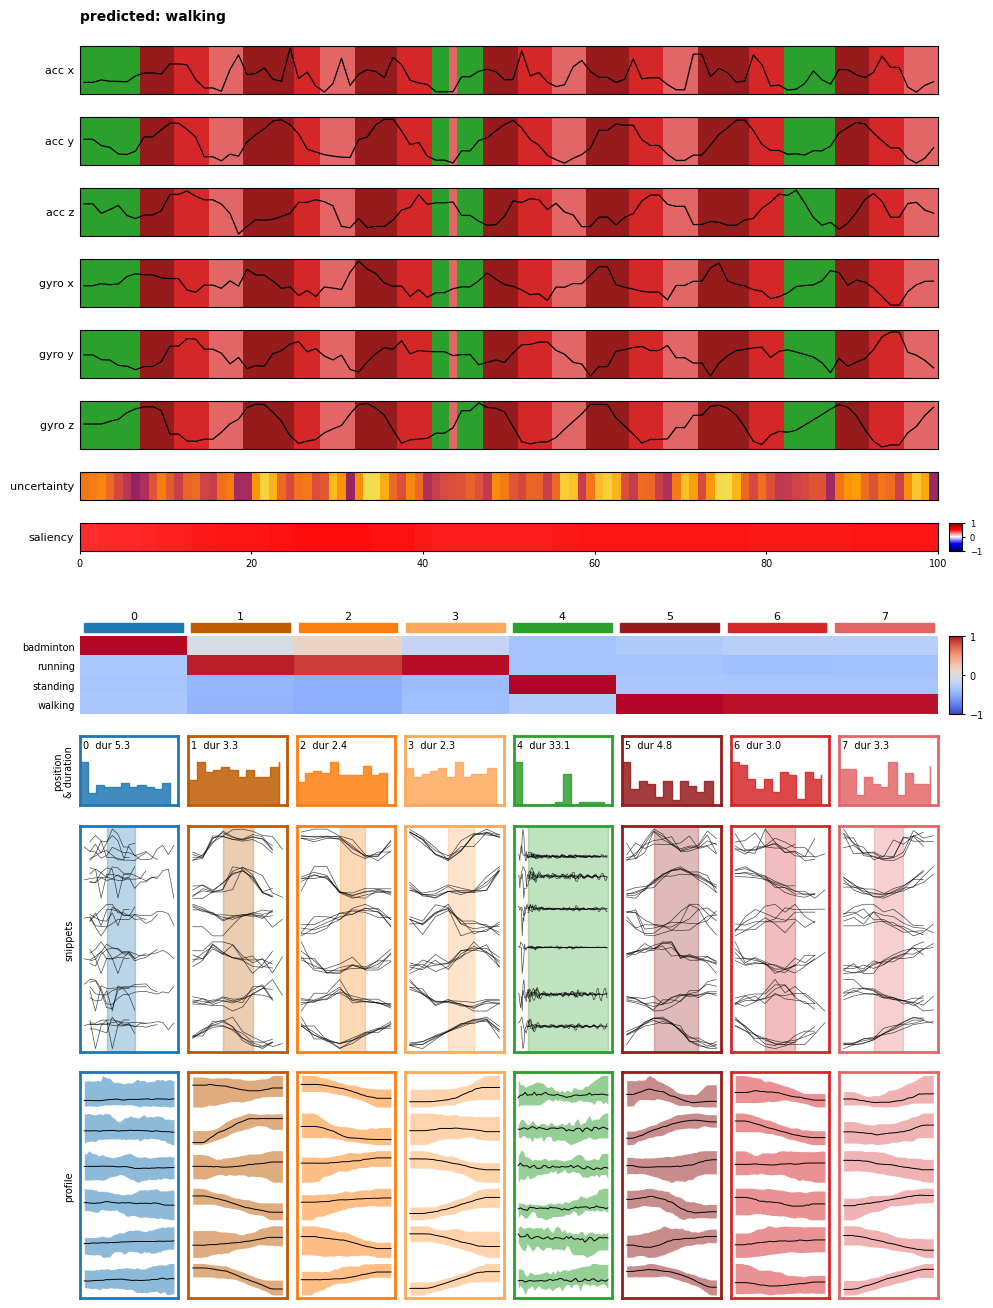

In [4]:
explainer.summarize(X_test[20], uncertainty=True, saliency=True);

Walking is decomposed into phases of the gait cycle; standing is one flat concept; the concepts
correlate with the activities. The numbers behind the figure are attributes: `snippets`, `profiles`,
`positions`, `durations`, `correlation`.

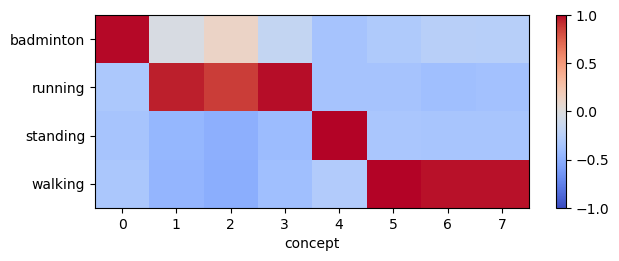

In [5]:
plt.figure(figsize=(7, 2.5))
plt.imshow(explainer.correlation.T, cmap="coolwarm", vmin=-1, vmax=1, aspect="auto")
plt.yticks(range(len(explainer.classes)), [classes[c] for c in explainer.classes]); plt.xlabel("concept")
plt.colorbar();

## Citation

If you use nave-xai, please cite the paper:

```bibtex
@article{boubekki2024nave,
  title   = {Multi-Depth Concept Extraction for Post-Hoc Vision Encoder Explanation},
  author  = {Boubekki, Ahc{\`e}ne and Fadel, Samuel G. and Mair, Sebastian},
  journal = {arXiv preprint arXiv:2411.19700},
  year    = {2024}
}
```